In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
candidate_results = pd.read_csv(
    "../data/evaluation/candidate_results.csv"
)

evaluation_queries = pd.read_csv(
    "../data/evaluation/evaluation_queries.csv"
)

df = pd.read_csv(
    "../data/processed/image_metadata.csv"
)

In [ ]:
def show_query(query_id):
    query = evaluation_queries[
        evaluation_queries["query_id"] == query_id
    ].iloc[0]

    print("Query ID:", query_id)
    print("Room:", query["room"])
    print("Style:", query["style"])
    print("Path:", query["path"])

    image = Image.open(query["path"])
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

In [ ]:
show_query(0)

In [ ]:
def show_candidates(query_id):
    results = candidate_results[
        candidate_results["query_id"] == query_id
    ].sort_values(["method", "rank"])

    for method in ["CLIP", "ResNet", "Color Histogram"]:

        method_results = results[
            results["method"] == method
        ]

        print("\n==============================")
        print(method)
        print("==============================")

        for _, row in method_results.iterrows():

            print(
                f"Rank {row['rank']} | "
                f"Similarity: {row['similarity']:.4f}"
            )

            image = Image.open(row["candidate_path"])

            plt.figure(figsize=(4, 4))
            plt.imshow(image)
            plt.axis("off")
            plt.show()

In [ ]:
show_candidates(0)

In [ ]:
human_labels = candidate_results[
    [
        "query_id",
        "method",
        "rank",
        "candidate_index",
        "candidate_path",
        "candidate_room",
        "candidate_style",
        "similarity"
    ]
].copy()

human_labels["human_relevant"] = pd.NA

human_labels.head()

In [ ]:
human_labels.to_csv(
    "../data/evaluation/human_labels.csv",
    index=False
)

print(
    "Created labeling file with",
    len(human_labels),
    "candidates"
)

In [ ]:
def label_candidate(query_id, method, rank, label):

    mask = (
        (human_labels["query_id"] == query_id) &
        (human_labels["method"] == method) &
        (human_labels["rank"] == rank)
    )

    if not mask.any():
        print("Candidate not found.")
        return

    human_labels.loc[mask, "human_relevant"] = label

    print(
        f"Labeled Query {query_id} | "
        f"{method} | Rank {rank} | "
        f"Label = {label}"
    )

In [ ]:
def review_query(query_id):
    query = evaluation_queries[
        evaluation_queries["query_id"] == query_id
    ].iloc[0]

    print("=" * 60)
    print(f"QUERY {query_id}")
    print(f"Room: {query['room']} | Style: {query['style']}")
    print("=" * 60)

    plt.figure(figsize=(5, 5))
    plt.imshow(Image.open(query["path"]))
    plt.title("QUERY IMAGE")
    plt.axis("off")
    plt.show()

    results = candidate_results[
        candidate_results["query_id"] == query_id
    ].sort_values(["method", "rank"])

    for method in ["CLIP", "ResNet", "Color Histogram"]:

        print(f"\n========== {method} ==========")

        method_results = results[
            results["method"] == method
        ]

        for _, row in method_results.iterrows():

            print(
                f"Rank {row['rank']} | "
                f"Similarity: {row['similarity']:.4f}"
            )

            plt.figure(figsize=(3, 3))
            plt.imshow(Image.open(row["candidate_path"]))
            plt.title(
                f"{method} | Rank {row['rank']}"
            )
            plt.axis("off")
            plt.show()

In [ ]:
review_query(0)

In [ ]:
def interactive_labeling():
    global human_labels

    # Only candidates that haven't been labeled yet
    remaining = human_labels[
        human_labels["human_relevant"].isna()
    ]

    print(f"Remaining labels: {len(remaining)}")

    for idx, row in remaining.iterrows():

        query_id = row["query_id"]
        method = row["method"]
        rank = row["rank"]

        # Find query information
        query = evaluation_queries[
            evaluation_queries["query_id"] == query_id
        ].iloc[0]

        print("\n" + "=" * 60)
        print(f"Query {query_id}")
        print(f"Room: {query['room']} | Style: {query['style']}")
        print(f"Method: {method} | Rank: {rank}")
        print(f"Similarity: {row['similarity']:.4f}")
        print("=" * 60)

        # Show query
        plt.figure(figsize=(4, 4))
        plt.imshow(Image.open(query["path"]))
        plt.title("QUERY")
        plt.axis("off")
        plt.show()

        # Show candidate
        plt.figure(figsize=(4, 4))
        plt.imshow(Image.open(row["candidate_path"]))
        plt.title(f"{method} -- Rank {rank}")
        plt.axis("off")
        plt.show()

        # Ask for label
        while True:
            answer = input(
                "Visually similar? 1 = Yes, 0 = No, q = Quit: "
            ).strip()

            if answer in ["0", "1"]:
                human_labels.loc[
                    idx, "human_relevant"
                ] = int(answer)
                break

            elif answer.lower() == "q":
                human_labels.to_csv(
                    "../data/evaluation/human_labels.csv",
                    index=False
                )

                print("Progress saved.")
                return

            else:
                print("Please enter 1, 0, or q.")

        # Save after every label
        human_labels.to_csv(
            "../data/evaluation/human_labels.csv",
            index=False
        )

    print("\nAll candidates have been labeled!")

In [ ]:
interactive_labeling()

In [ ]:
interactive_labeling()

In [ ]:
interactive_labeling()

In [ ]:
interactive_labeling()

In [ ]:
interactive_labeling()

In [ ]:
candidate_results = pd.read_csv(
    "../data/evaluation/candidate_results.csv"
)

evaluation_queries = pd.read_csv(
    "../data/evaluation/evaluation_queries.csv"
)

df = pd.read_csv(
    "../data/processed/image_metadata.csv"
)

human_labels = pd.read_csv(
    "../data/evaluation/human_labels.csv"
)

In [ ]:
print(
    "Already labeled:",
    human_labels["human_relevant"].notna().sum()
)

print(
    "Remaining:",
    human_labels["human_relevant"].isna().sum()
)

print(
    "Total:",
    len(human_labels)
)

In [ ]:
human_labels.to_csv(
    "../data/evaluation/human_labels.csv",
    index=False
)

In [ ]:
def precision_at_5(method):
    results = human_labels[
        human_labels["method"] == method
    ]

    return results["human_relevant"].mean()

In [ ]:
clip_p5 = precision_at_5("CLIP")
resnet_p5 = precision_at_5("ResNet")
color_p5 = precision_at_5("Color Histogram")

print(f"CLIP Precision@5: {clip_p5:.3f}")
print(f"ResNet Precision@5: {resnet_p5:.3f}")
print(f"Color Histogram Precision@5: {color_p5:.3f}")

In [ ]:
import pandas as pd

human_labels = pd.read_csv(
    "../data/evaluation/human_labels.csv"
)

evaluation_queries = pd.read_csv(
    "../data/evaluation/evaluation_queries.csv"
)

df = pd.read_csv(
    "../data/processed/image_metadata.csv"
)

print(human_labels.shape)
print(evaluation_queries.shape)
print(human_labels.columns.tolist())

In [ ]:
room_eval = human_labels.copy()

query_rooms = evaluation_queries[
    ["query_id", "room"]
].rename(
    columns={"room": "query_room"}
)

room_eval = room_eval.merge(
    query_rooms,
    on="query_id",
    how="left"
)

room_eval["same_room"] = (
    room_eval["candidate_room"]
    == room_eval["query_room"]
)

room_eval["room_consistent_relevant"] = (
    (room_eval["human_relevant"] == 1)
    & room_eval["same_room"]
).astype(int)

In [ ]:
print(room_eval.shape)

print(
    room_eval[
        [
            "query_id",
            "candidate_room",
            "query_room",
            "human_relevant",
            "same_room",
            "room_consistent_relevant"
        ]
    ].head(10)
)

In [ ]:
room_scores = (
    room_eval
    .groupby("method")["room_consistent_relevant"]
    .mean()
)

print(room_scores)

In [ ]:
for method, score in room_scores.items():
    print(
        f"{method} room-consistent Precision@5: "
        f"{score:.3f}"
    )

In [ ]:
visual_scores = (
    human_labels
    .groupby("method")["human_relevant"]
    .mean()
)

for method, score in visual_scores.items():
    print(
        f"{method} visual Precision@5: "
        f"{score:.3f}"
    )

In [ ]:
query_precision = (
    human_labels
    .groupby(["query_id", "method"])["human_relevant"]
    .mean()
    .reset_index(name="precision_at_5")
)

query_precision.head(10)

In [ ]:
summary = (
    query_precision
    .groupby("method")["precision_at_5"]
    .agg(["mean", "std"])
    .reset_index()
)

summary

In [ ]:
import numpy as np

summary["se"] = (
    summary["std"] /
    np.sqrt(30)
)

summary["ci_lower"] = (
    summary["mean"] -
    1.96 * summary["se"]
)

summary["ci_upper"] = (
    summary["mean"] +
    1.96 * summary["se"]
)

summary

In [ ]:
summary["ci_lower"] = summary["ci_lower"].clip(0, 1)
summary["ci_upper"] = summary["ci_upper"].clip(0, 1)

summary

In [ ]:
room_query_precision = (
    room_eval
    .groupby(
        ["query_id", "method"]
    )["room_consistent_relevant"]
    .mean()
    .reset_index(
        name="room_precision_at_5"
    )
)

In [ ]:
room_summary = (
    room_query_precision
    .groupby("method")["room_precision_at_5"]
    .agg(["mean", "std"])
    .reset_index()
)

room_summary

In [ ]:
room_summary["se"] = (
    room_summary["std"] /
    np.sqrt(30)
)

room_summary["ci_lower"] = (
    room_summary["mean"] -
    1.96 * room_summary["se"]
)

room_summary["ci_upper"] = (
    room_summary["mean"] +
    1.96 * room_summary["se"]
)

room_summary["ci_lower"] = room_summary["ci_lower"].clip(0, 1)
room_summary["ci_upper"] = room_summary["ci_upper"].clip(0, 1)

room_summary

In [ ]:
results_table = summary[
    ["method", "mean", "ci_lower", "ci_upper"]
].copy()

results_table = results_table.rename(
    columns={
        "mean": "visual_precision_at_5",
        "ci_lower": "visual_ci_lower",
        "ci_upper": "visual_ci_upper"
    }
)

results_table = results_table.merge(
    room_summary[
        [
            "method",
            "mean",
            "ci_lower",
            "ci_upper"
        ]
    ],
    on="method"
)

results_table = results_table.rename(
    columns={
        "mean": "room_precision_at_5",
        "ci_lower": "room_ci_lower",
        "ci_upper": "room_ci_upper"
    }
)

results_table

In [ ]:
results_table.to_csv(
    "../data/evaluation/results_summary.csv",
    index=False
)

In [ ]:
query_precision.head(15)

In [ ]:
clip_resnet = query_precision.pivot(
    index="query_id",
    columns="method",
    values="precision_at_5"
)

clip_resnet["CLIP_minus_ResNet"] = (
    clip_resnet["CLIP"]
    - clip_resnet["ResNet"]
)

clip_resnet[
    ["CLIP", "ResNet", "CLIP_minus_ResNet"]
].head()

In [ ]:
print(
    "Mean CLIP advantage over ResNet:",
    clip_resnet["CLIP_minus_ResNet"].mean()
)

In [ ]:
clip_resnet["CLIP_minus_Color"] = (
    clip_resnet["CLIP"]
    - clip_resnet["Color Histogram"]
)

print(
    "Mean CLIP advantage over Color Histogram:",
    clip_resnet["CLIP_minus_Color"].mean()
)

In [ ]:
from scipy.stats import wilcoxon

clip_vs_resnet = wilcoxon(
    clip_resnet["CLIP"],
    clip_resnet["ResNet"]
)

clip_vs_color = wilcoxon(
    clip_resnet["CLIP"],
    clip_resnet["Color Histogram"]
)

resnet_vs_color = wilcoxon(
    clip_resnet["ResNet"],
    clip_resnet["Color Histogram"]
)

print("CLIP vs ResNet")
print("Statistic:", clip_vs_resnet.statistic)
print("p-value:", clip_vs_resnet.pvalue)

print("\nCLIP vs Color Histogram")
print("Statistic:", clip_vs_color.statistic)
print("p-value:", clip_vs_color.pvalue)

print("\nResNet vs Color Histogram")
print("Statistic:", resnet_vs_color.statistic)
print("p-value:", resnet_vs_color.pvalue)

In [ ]:
import pandas as pd

results_table = pd.DataFrame({
    "Method": [
        "CLIP",
        "ResNet",
        "Color Histogram"
    ],
    "Visual Precision@5": [
        0.873333,
        0.713333,
        0.460000
    ],
    "Visual CI Lower": [
        0.792530,
        0.609223,
        0.332319
    ],
    "Visual CI Upper": [
        0.954137,
        0.817443,
        0.587681
    ],
    "Room Precision@5": [
        0.660000,
        0.426667,
        0.153333
    ],
    "Room CI Lower": [
        0.546996,
        0.311214,
        0.083809
    ],
    "Room CI Upper": [
        0.773004,
        0.542119,
        0.222858
    ]
})

results_table

In [ ]:
display_table = results_table.copy()

display_table["Visual Precision@5"] = (
    display_table["Visual Precision@5"] * 100
).round(1)

display_table["Visual 95% CI"] = (
    (display_table["Visual CI Lower"] * 100).round(1).astype(str)
    + "–" +
    (display_table["Visual CI Upper"] * 100).round(1).astype(str)
)

display_table["Room Precision@5"] = (
    display_table["Room Precision@5"] * 100
).round(1)

display_table["Room 95% CI"] = (
    (display_table["Room CI Lower"] * 100).round(1).astype(str)
    + "–" +
    (display_table["Room CI Upper"] * 100).round(1).astype(str)
)

display(
    display_table[
        ["Method", "Visual Precision@5", "Visual 95% CI",
         "Room Precision@5", "Room 95% CI"]
    ]
)

### FINAL RESULTS

In [1]:
import pandas as pd

results_table = pd.DataFrame({
    "Method": [
        "CLIP",
        "ResNet",
        "Color Histogram"
    ],
    "Visual Precision@5": [
        0.873333,
        0.713333,
        0.460000
    ],
    "Visual CI Lower": [
        0.792530,
        0.609223,
        0.332319
    ],
    "Visual CI Upper": [
        0.954137,
        0.817443,
        0.587681
    ],
    "Room Precision@5": [
        0.660000,
        0.426667,
        0.153333
    ],
    "Room CI Lower": [
        0.546996,
        0.311214,
        0.083809
    ],
    "Room CI Upper": [
        0.773004,
        0.542119,
        0.222858
    ]
})

results_table

,Method,Visual Precision@5,Visual CI Lower,Visual CI Upper,Room Precision@5,Room CI Lower,Room CI Upper
0,CLIP,0.873333,0.792530,0.954137,0.660000,0.546996,0.773004
1,ResNet,0.713333,0.609223,0.817443,0.426667,0.311214,0.542119
2,Color Histogram,0.460000,0.332319,0.587681,0.153333,0.083809,0.222858


In [2]:
display_table = results_table.copy()

display_table["Visual Precision@5"] = (
    display_table["Visual Precision@5"] * 100
).round(1).astype(str) + "%"

display_table["Visual 95% CI"] = (
    (display_table["Visual CI Lower"] * 100).round(1).astype(str)
    + "–" +
    (display_table["Visual CI Upper"] * 100).round(1).astype(str)
    + "%"
)

display_table["Room Precision@5"] = (
    display_table["Room Precision@5"] * 100
).round(1).astype(str) + "%"

display_table["Room 95% CI"] = (
    (display_table["Room CI Lower"] * 100).round(1).astype(str)
    + "–" +
    (display_table["Room CI Upper"] * 100).round(1).astype(str)
    + "%"
)

display(
    display_table[
        [
            "Method",
            "Visual Precision@5",
            "Visual 95% CI",
            "Room Precision@5",
            "Room 95% CI"
        ]
    ]
)

,Method,Visual Precision@5,Visual 95% CI,Room Precision@5,Room 95% CI
0,CLIP,87.3%,79.3–95.4%,66.0%,54.7–77.3%
1,ResNet,71.3%,60.9–81.7%,42.7%,31.1–54.2%
2,Color Histogram,46.0%,33.2–58.8%,15.3%,8.4–22.3%


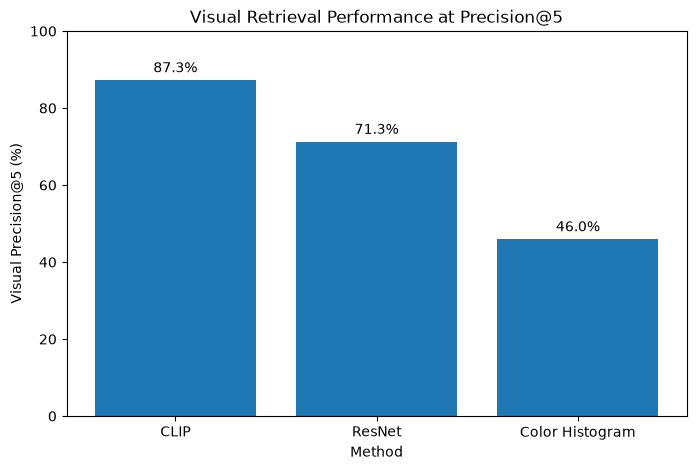

In [3]:
import matplotlib.pyplot as plt

methods = ["CLIP", "ResNet", "Color Histogram"]
precision = [87.3, 71.3, 46.0]

plt.figure(figsize=(8, 5))

plt.bar(methods, precision)

plt.ylabel("Visual Precision@5 (%)")
plt.xlabel("Method")
plt.title("Visual Retrieval Performance at Precision@5")
plt.ylim(0, 100)

for i, value in enumerate(precision):
    plt.text(i, value + 2, f"{value}%", ha="center")

plt.show()